# MenoPhenotype — Notebook 6: Feature Selection

**Course stage covered:** Stage 8 (Feature Selection).
**Input:** `artifacts/baseline_train_features.csv`, `artifacts/quality_meta.json`,
`artifacts/screener_validation_features.csv`.
**Output:** `artifacts/feature_sets.json` (recommended clustering feature set + evidence).

With no target variable, "relevant" cannot mean "predictive". Five unsupervised criteria are used together:
(1) near-constant screen, (2) redundancy via correlation, (3) multicollinearity via VIF, (4) clusterability
(Hopkins statistic), (5) how structure changes when a domain is added/removed (PCA + silhouette ablation).
Everything below runs on the **training split only**, so the choice of feature set cannot be influenced by
the held-out test data.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 100
RNG = 42
ART = Path('artifacts')
qmeta = json.load(open(ART / 'quality_meta.json'))
HORM_COLS, ANTHRO_COL = qmeta['HORM_COLS'], ['BMI0', 'WHR']

Xtr = pd.read_csv(ART / 'baseline_train_features.csv').set_index('SWANID')
sv = pd.read_csv(ART / 'screener_validation_features.csv').set_index('SWANID')
print(Xtr.shape, sv.shape)


(2632, 29) (8713, 11)


## A. Candidate feature sets

| Set | Contents | Purpose |
|---|---|---|
| **A — symptoms** | the 18 symptom items | primary phenotyping ("what do women *report*?") |
| **B — symptoms + mood** | A + `cesd_mean` | adds a validated depressive-symptom score |
| **C — full** | B + 6 hormones + `BMI0`, `WHR`, `AGE0`, `SPORTS0` | tests whether clinical/biological context adds structure |

(CESD items and domain composite scores are not included as separate columns — see Notebook 3: they are
averages of items already present, so including both would double-count that domain by construction.)


In [2]:
symp_domains = {'vasomotor': ['HOTFLAS0','NITESWE0','COLDSWE0'],
                 'psychological': ['FEELBLU0','IRRITAB0','NRVOUS0','FORGET0','MOODCHG0','FEARFULA0'],
                 'somatic': ['STIFF0','HDACHE0','VAGINDR0','HARTRAC0','DIZZY0','LEAKURI0'],
                 'sleep': ['TRBLSLE0','WAKEUP0','WAKEARL0']}
SET_A = sum(symp_domains.values(), [])
SET_B = SET_A + ['cesd_mean']
SET_C = SET_B + HORM_COLS + ANTHRO_COL + ['AGE0', 'SPORTS0']
SETS = {'A: symptoms': SET_A, 'B: +mood': SET_B, 'C: full': SET_C}
print({k: len(v) for k, v in SETS.items()})


{'A: symptoms': 18, 'B: +mood': 19, 'C: full': 29}


### A.1 Near-constant screen

In [3]:
dom = {c: Xtr[c].round(2).value_counts(normalize=True).iloc[0] for c in SET_C}
dom = pd.Series(dom).sort_values(ascending=False)
print("Share of training women in the single most common (standardised) value:")
print((dom * 100).round(1).head(8).to_string())
print("\nItems with >=95% in one level (would be dropped):", list(dom.index[dom >= 0.95]) or 'none')


Share of training women in the single most common (standardised) value:
COLDSWE0     89.2
FEARFULA0    81.2
VAGINDR0     80.9
DIZZY0       76.7
HOTFLAS0     73.5
NITESWE0     71.0
HARTRAC0     69.8
LEAKURI0     69.0

Items with >=95% in one level (would be dropped): none


### A.2 Redundancy: correlation among training features

Strongest feature pairs (Spearman r):
IRRITAB0  NRVOUS0      0.59
          MOODCHG0     0.58
FEELBLU0  cesd_mean    0.57
          MOODCHG0     0.57
          NRVOUS0      0.56
          IRRITAB0     0.55
NRVOUS0   MOODCHG0     0.52
WAKEUP0   WAKEARL0     0.52

Pairs with |r| >= 0.80 (would drop one): 0


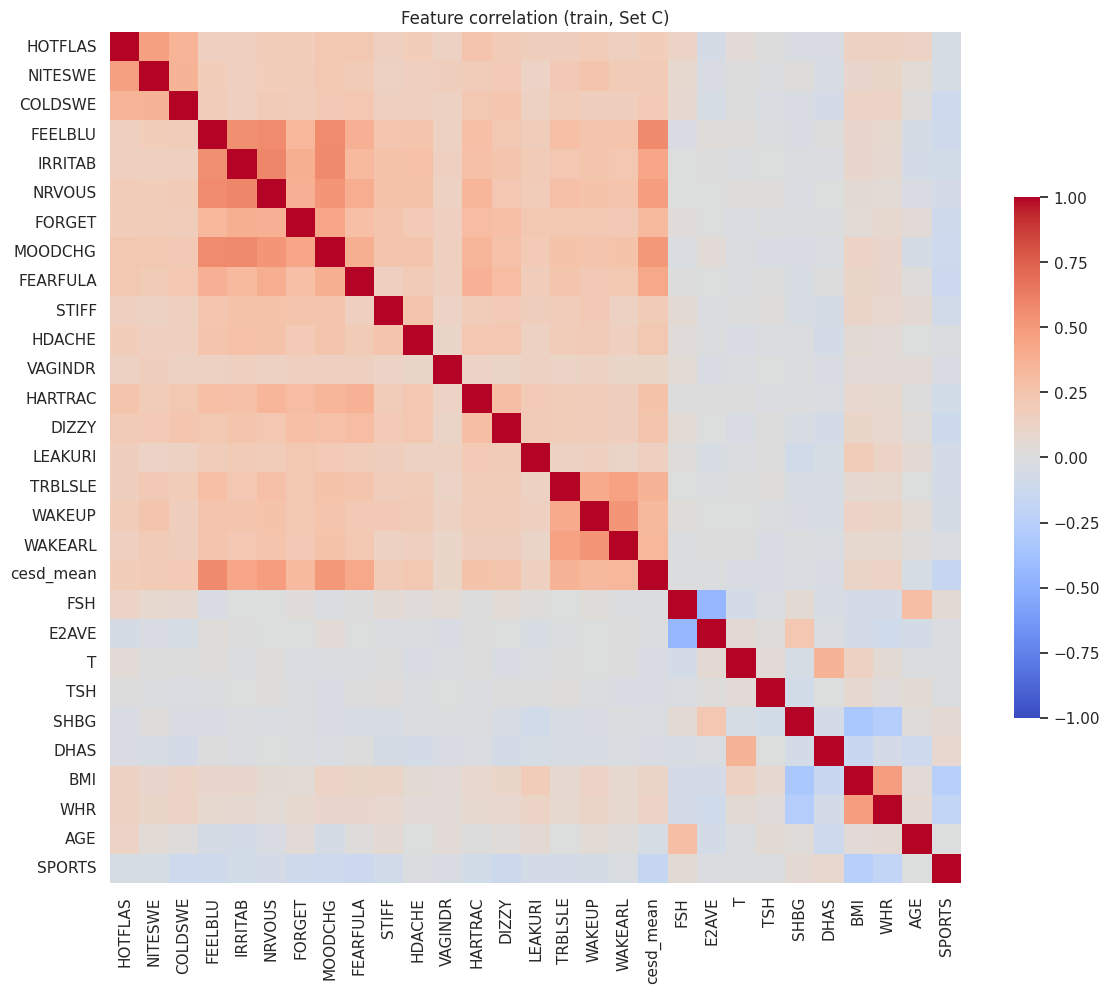

In [4]:
corr = Xtr[SET_C].corr(method='spearman')
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
top = pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8)
print("Strongest feature pairs (Spearman r):"); print(top.round(2).to_string())
print("\nPairs with |r| >= 0.80 (would drop one):", int((pairs.abs() >= 0.80).sum()))

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': .6},
            xticklabels=[c.replace('0', '') for c in corr.columns], yticklabels=[c.replace('0', '') for c in corr.columns])
plt.title('Feature correlation (train, Set C)'); plt.tight_layout(); plt.show()


### A.3 Multicollinearity: VIF

In [5]:
def vif(X):
    r = np.corrcoef(X.values, rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(r)), index=X.columns)

v = vif(Xtr[SET_C]).sort_values(ascending=False)
print("Highest VIF, Set C (rule of thumb: >5 concerning, >10 severe):"); print(v.round(2).head(8).to_string())
print("\nMax VIF Set A:", vif(Xtr[SET_A]).max().round(2), "| Set B:", vif(Xtr[SET_B]).max().round(2))


Highest VIF, Set C (rule of thumb: >5 concerning, >10 severe):
FEELBLU0     2.31
MOODCHG0     2.31
NRVOUS0      2.26
IRRITAB0     2.20
cesd_mean    1.98
WAKEARL0     1.66
FEARFULA0    1.64
WAKEUP0      1.60

Max VIF Set A: 2.27 | Set B: 2.3


### A.4 Clusterability: Hopkins statistic (0.5 = random, -> 1 = clustered)

In [6]:
def hopkins(X, m=300, seed=0, reps=20):
    X = np.asarray(X, float); n, d = X.shape; m = min(m, n // 10)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    lo, hi = X.min(0), X.max(0); out = []
    for r in range(reps):
        rs = np.random.RandomState(seed + r)
        idx = rs.choice(n, m, replace=False)
        w = nn.kneighbors(X[idx], 2)[0][:, 1]
        u = nn.kneighbors(rs.uniform(lo, hi, (m, d)), 1)[0][:, 0]
        out.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(out)), float(np.std(out))

hopkins_results = {}
for name, cols in SETS.items():
    h, s = hopkins(Xtr[cols])
    hopkins_results[name] = h
    print(f"Set {name:12s} ({len(cols):2d} feats)  Hopkins = {h:.3f} +/- {s:.3f}")
print("\nCaution: ordinal items with many ties bias Hopkins upward; read as a relative comparison,")
print("not absolute proof clusters exist.")


Set A: symptoms  (18 feats)  Hopkins = 0.750 +/- 0.009


Set B: +mood     (19 feats)  Hopkins = 0.744 +/- 0.007


Set C: full      (29 feats)  Hopkins = 0.677 +/- 0.004

Caution: ordinal items with many ties bias Hopkins upward; read as a relative comparison,
not absolute proof clusters exist.


### A.5 PCA: dimensionality needed per set

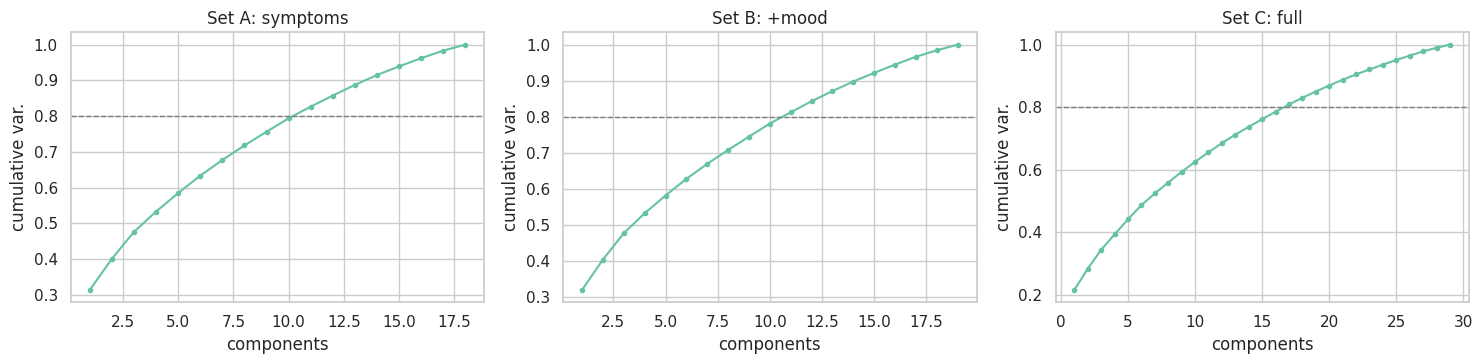

,set,n_features,PC1 var %,PCs for 80%,PCs for 90%
0,A: symptoms,18,31.4,11,14
1,B: +mood,19,32.0,11,15
2,C: full,29,21.5,17,22


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
pca_rows = []
for ax, (name, cols) in zip(axes, SETS.items()):
    p = PCA().fit(Xtr[cols]); cum = np.cumsum(p.explained_variance_ratio_)
    ax.plot(range(1, len(cum) + 1), cum, marker='o', ms=3); ax.axhline(0.8, ls='--', c='grey', lw=1)
    ax.set_title(f'Set {name}'); ax.set_xlabel('components'); ax.set_ylabel('cumulative var.')
    pca_rows.append({'set': name, 'n_features': len(cols), 'PC1 var %': p.explained_variance_ratio_[0] * 100,
                      'PCs for 80%': int(np.searchsorted(cum, 0.80) + 1), 'PCs for 90%': int(np.searchsorted(cum, 0.90) + 1)})
plt.tight_layout(); plt.show()
pd.DataFrame(pca_rows).round(1)


### A.6 Silhouette ablation (K-Means, k=2..6) — diagnostic, not the final model

In [8]:
def best_sil(X, ks=range(2, 7)):
    res = {}
    for k in ks:
        lab = KMeans(k, n_init=10, random_state=RNG).fit_predict(X)
        res[k] = silhouette_score(X, lab, sample_size=min(2000, len(X)), random_state=RNG)
    kb = max(res, key=res.get); return kb, res[kb], res

abl = []
for name, cols in SETS.items():
    kb, sb, _ = best_sil(Xtr[cols]); abl.append({'feature set': name, 'n_feats': len(cols), 'best k': kb, 'silhouette': round(sb, 3)})
domains = {**{f'symptoms:{d}': c for d, c in symp_domains.items()}, 'mood (cesd)': ['cesd_mean'],
           'hormones': HORM_COLS, 'anthro (BMI,WHR)': ANTHRO_COL, 'context (age,exercise)': ['AGE0', 'SPORTS0']}
for d, cols in domains.items():
    keep_cols = [c for c in SET_C if c not in cols]
    kb, sb, _ = best_sil(Xtr[keep_cols]); abl.append({'feature set': f'C minus {d}', 'n_feats': len(keep_cols), 'best k': kb, 'silhouette': round(sb, 3)})
pd.DataFrame(abl)


,feature set,n_feats,best k,silhouette
0,A: symptoms,18,2,0.354
1,B: +mood,19,2,0.342
2,C: full,29,2,0.237
3,C minus symptoms:vasomotor,26,2,0.236
4,C minus symptoms:psychological,23,2,0.198
5,C minus symptoms:somatic,23,2,0.242
6,C minus symptoms:sleep,26,2,0.249
7,C minus mood (cesd),28,2,0.248
8,C minus hormones,23,2,0.289
9,"C minus anthro (BMI,WHR)",27,2,0.251


## A.7 Reading the results together

**Near-constant / VIF:** nothing is >=95% one value; the highest VIF anywhere is ~2.3 (well under the usual
concern threshold of 5) — no severe multicollinearity, nothing needs dropping on those grounds.

**Hopkins:** clusterability *falls* as more feature types are added (Set A highest, Set C lowest) — the
hormone/anthro/lifestyle block dilutes the clustering signal rather than sharpening it.

**PCA:** consistent with Hopkins — Set A needs the fewest components for 80% variance; Set C is the most
diffuse.

**Silhouette ablation:** Set A scores the best of the three feature sets. Within Set C, removing the
**psychological** domain hurts silhouette the most (it's the biggest contributor to whatever separable
structure the full set has); removing **hormones** from Set C actually *improves* silhouette — at this hard
clustering (K-Means) diagnostic stage, the hormone panel adds noise rather than signal.

**Recommendation:** use **Set A (18 symptom items)** as the primary clustering input for the modelling
notebook. Carry Set B and Set C forward only as robustness checks. Keep hormones/BMI/age/exercise, plus the
domain composite scores from Notebook 3, for **profiling clusters after they are formed** — not for forming
them — matching the blueprint's rationale for soft (GMM) clustering over overlapping profiles.

One caveat: every silhouette figure above points to k=2 because K-Means-at-k=2 is used purely to *compare
feature sets*, not to choose the final number of clusters. That selection (elbow, silhouette-vs-k, gap
statistic, cross-checked with GMM/Agglomerative) is done properly in the modelling notebook.


## B. Screener validation set: feature selection

Prevalence range: 12.2% - 50.6%  (none near-constant -> no item dropped)

Strongest phi correlations:
HOTFLASH  NISWEAT    0.49
TENSE     DEPRESS    0.45
          IRRITAB    0.38
DEPRESS   IRRITAB    0.35
FORGET    TENSE      0.30
Pairs with |phi| >= 0.80: 0 | max VIF: 1.45


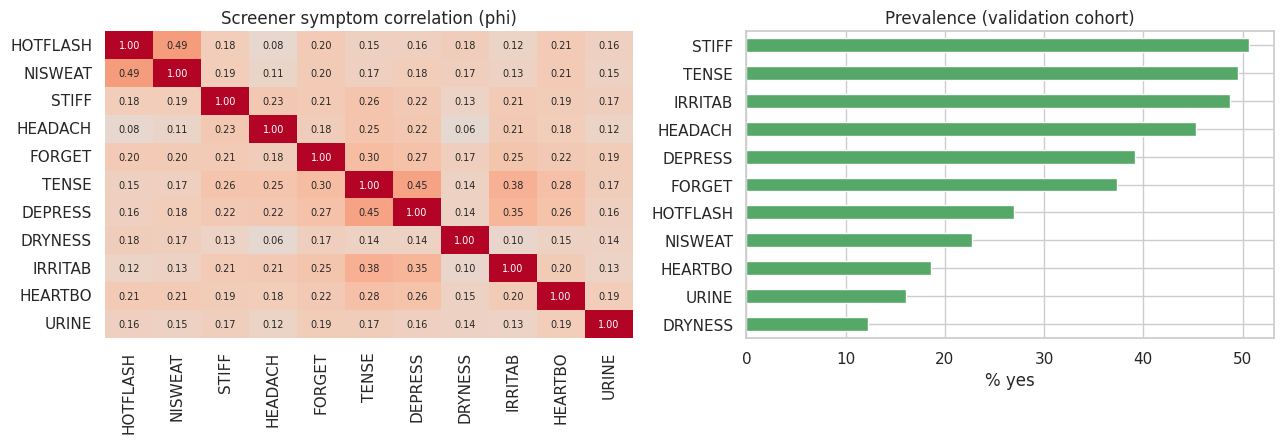


All 11 items kept: no near-constant items, no severe collinearity.


In [9]:
prev = sv.mean().sort_values()
print("Prevalence range: %.1f%% - %.1f%%  (none near-constant -> no item dropped)" % (prev.min()*100, prev.max()*100))
phi = sv.corr()
pp = phi.where(np.triu(np.ones(phi.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("\nStrongest phi correlations:"); print(pp.head(5).round(2).to_string())
print("Pairs with |phi| >= 0.80:", int((pp.abs() >= 0.8).sum()), "| max VIF:", vif(sv.astype(float)).max().round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.heatmap(phi, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax[0], cbar=False)
ax[0].set_title('Screener symptom correlation (phi)')
prev.mul(100).plot.barh(ax=ax[1], color='#55A868'); ax[1].set_xlabel('% yes'); ax[1].set_title('Prevalence (validation cohort)')
plt.tight_layout(); plt.show()
print("\nAll 11 items kept: no near-constant items, no severe collinearity.")


## C. Save the feature-selection decision

In [10]:
result = {
    'sets': {'A': SET_A, 'B': SET_B, 'C': SET_C},
    'recommended_set': 'A',
    'hopkins': hopkins_results,
    'ablation_summary': abl,
    'screener_features_kept': list(sv.columns),
    'rationale': ("Set A (18 symptom items) has the highest Hopkins statistic, needs the fewest PCA "
                  "components for 80% variance, and scores best on the silhouette ablation. Hormones/BMI/"
                  "age/exercise are reserved for post-hoc cluster profiling rather than clustering inputs."),
}
json.dump(result, open(ART / 'feature_sets.json', 'w'), indent=2)
print("Saved feature_sets.json")


Saved feature_sets.json


### Summary

| Item | Decision |
|---|---|
| Recommended clustering input | Set A — 18 symptom items |
| Robustness checks | Set B (+mood), Set C (full clinical) carried forward |
| Reserved for profiling only | Hormone panel, BMI/WHR, age, exercise, CESD mean, domain composite scores |
| Screener | all 11 binary items kept (no near-constant items, no severe collinearity) |
| Next notebook | Notebook 7 — Baseline model + K-Means / Agglomerative / DBSCAN / GMM sweep |
